# Data copying test

**Can the test detect when a synthetic/generated sample is suspiciously closer to the training data than genuine held-out data?**


This experiment evaluates whether a data-copying diagnostic can detect
when a candidate sample contains observations copied directly from a
reference/training dataset.

Unlike the previous defect experiments, data copying is not introduced by
modifying an existing observation. Instead, part of a fresh candidate
sample is replaced with exact examples from the training/reference set.

The experiment uses three disjoint roles:

- **T (training/reference):** data that could potentially be copied.
- **P (fresh real):** held-out real data used as a baseline.
- **Q (candidate):** held-out data in which controlled copying is injected.

Copying prevalence is evaluated at 0%, 10%, 30%, and 60%.

The primary known-answer expectation is that Q should become increasingly
closer to T as more training examples are copied into Q, while P remains
unchanged.

In [1]:
import importlib
import numpy as np
import pandas as pd

import src.paths as paths
import src.io_utils as io_utils

importlib.reload(paths)
importlib.reload(io_utils)

from src.paths import get_project_paths
from src.io_utils import load_id_file

PATHS = get_project_paths()
DATA_DIR = PATHS["processed"]
RESULTS_DIR = PATHS["results"]
WEEK7_RESULTS_DIR = RESULTS_DIR / "week7"

WEEK7_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PATHS["root"])
print("Processed data:", DATA_DIR)
print("Week 7 results:", WEEK7_RESULTS_DIR)

Project root: /Users/jessica/fidelity-metric-lab
Processed data: /Users/jessica/fidelity-metric-lab/data/processed
Week 7 results: /Users/jessica/fidelity-metric-lab/results/week7


In [2]:
required_files = [
    DATA_DIR / "over_polished_sms_split.csv",
    DATA_DIR / "over_polished_reference_embeddings.npy",
    DATA_DIR / "over_polished_reference_embedding_message_ids.csv",
    DATA_DIR / "over_polished_embeddings_clean.npy",
    DATA_DIR / "over_polished_embedding_message_ids.csv"
]

missing = [p for p in required_files if not p.exists()]

if missing:
    print("Missing files:")
    for p in missing:
        print("-", p.name)
else:
    print("All Data-Copying input artifacts are available.")

All Data-Copying input artifacts are available.


In [3]:
sms_split = pd.read_csv(DATA_DIR / "over_polished_sms_split.csv")

T_embeddings = np.load(
    DATA_DIR / "over_polished_reference_embeddings.npy"
)

E_embeddings = np.load(
    DATA_DIR / "over_polished_embeddings_clean.npy"
)

T_ids = load_id_file(
    DATA_DIR,
    "over_polished_reference_embedding_message_ids.csv",
    id_column="message_id"
)

E_ids = load_id_file(
    DATA_DIR,
    "over_polished_embedding_message_ids.csv",
    id_column="message_id"
)

print("T embeddings:", T_embeddings.shape)
print("Evaluation embeddings:", E_embeddings.shape)
print("T IDs:", len(T_ids))
print("Evaluation IDs:", len(E_ids))

T embeddings: (700, 384)
Evaluation embeddings: (300, 384)
T IDs: 700
Evaluation IDs: 300


In [4]:
T_meta = (
    sms_split.loc[sms_split["split"] == "reference", ["message_id", "label"]]
    .set_index("message_id")
    .loc[T_ids]
    .reset_index()
)

E_meta = (
    sms_split.loc[sms_split["split"] == "evaluation", ["message_id", "label"]]
    .set_index("message_id")
    .loc[E_ids]
    .reset_index()
)

print("T metadata:", T_meta.shape)
print("Evaluation metadata:", E_meta.shape)

print("\nT labels:")
print(T_meta["label"].value_counts())

print("\nEvaluation labels:")
print(E_meta["label"].value_counts())

T metadata: (700, 2)
Evaluation metadata: (300, 2)

T labels:
label
ham     606
spam     94
Name: count, dtype: int64

Evaluation labels:
label
ham     260
spam     40
Name: count, dtype: int64


In [5]:
for name, X in [("T", T_embeddings), ("Evaluation", E_embeddings)]:
    assert X.shape[1] == 384
    assert np.isfinite(X).all()

    norms = np.linalg.norm(X, axis=1)
    assert np.allclose(norms, 1.0, atol=1e-5)

    print(
        name,
        "| shape =", X.shape,
        "| mean norm =", round(norms.mean(), 6)
    )

print("Embedding validation passed.")

T | shape = (700, 384) | mean norm = 1.0
Evaluation | shape = (300, 384) | mean norm = 1.0
Embedding validation passed.


In [6]:
from sklearn.model_selection import train_test_split

COPY_SPLIT_SEED = 42

P_idx, Q_idx = train_test_split(
    np.arange(len(E_ids)),
    train_size=150,
    test_size=150,
    random_state=COPY_SPLIT_SEED,
    stratify=E_meta["label"]
)

P_meta = E_meta.iloc[P_idx].copy().reset_index(drop=True)
Q_meta = E_meta.iloc[Q_idx].copy().reset_index(drop=True)

P_embeddings = E_embeddings[P_idx].copy()
Q_clean_embeddings = E_embeddings[Q_idx].copy()

print("P:", P_embeddings.shape)
print("Q:", Q_clean_embeddings.shape)

print("\nP labels:")
print(P_meta["label"].value_counts())

print("\nQ labels:")
print(Q_meta["label"].value_counts())

P: (150, 384)
Q: (150, 384)

P labels:
label
ham     130
spam     20
Name: count, dtype: int64

Q labels:
label
ham     130
spam     20
Name: count, dtype: int64


In [7]:
T_set = set(T_ids)
P_set = set(P_meta["message_id"])
Q_set = set(Q_meta["message_id"])

print("T ∩ P:", len(T_set & P_set))
print("T ∩ Q:", len(T_set & Q_set))
print("P ∩ Q:", len(P_set & Q_set))

assert T_set.isdisjoint(P_set)
assert T_set.isdisjoint(Q_set)
assert P_set.isdisjoint(Q_set)

print("T, P, and Q are fully disjoint.")

T ∩ P: 0
T ∩ Q: 0
P ∩ Q: 0
T, P, and Q are fully disjoint.


In [8]:
P_export = P_meta.copy()
P_export["role"] = "P"

Q_export = Q_meta.copy()
Q_export["role"] = "Q"

copying_split = pd.concat([P_export, Q_export], ignore_index=True)

copying_split.to_csv(
    DATA_DIR / "data_copying_eval_split.csv",
    index=False
)

print(copying_split["role"].value_counts())

role
P    150
Q    150
Name: count, dtype: int64


In [9]:
import src.data_copying as data_copying

importlib.reload(data_copying)

from src.data_copying import make_exact_copy_plan

COPY_SEVERITIES = [0.10, 0.30, 0.60]

copy_plan = make_exact_copy_plan(
    Q_meta,
    T_meta,
    severities=COPY_SEVERITIES,
    seed=42
)

display(
    copy_plan.groupby(["severity", "label"]).size()
)

severity  label
0.1       ham      13
          spam      2
0.3       ham      39
          spam      6
0.6       ham      78
          spam     12
dtype: int64

In [10]:
copy_ids = {
    s: set(copy_plan.loc[copy_plan["severity"] == s, "q_message_id"])
    for s in COPY_SEVERITIES
}

assert copy_ids[0.10].issubset(copy_ids[0.30])
assert copy_ids[0.30].issubset(copy_ids[0.60])

for severity in COPY_SEVERITIES:
    print(
        f"{severity:.0%}",
        "| copied Q slots =", len(copy_ids[severity])
    )

print("Nested copying validation passed.")

10% | copied Q slots = 15
30% | copied Q slots = 45
60% | copied Q slots = 90
Nested copying validation passed.


In [11]:
copy_plan.to_csv(
    DATA_DIR / "data_copying_exact_copy_plan.csv",
    index=False
)

print("Copying plan saved.")

Copying plan saved.


In [ ]:
# build the 4 Q
importlib.reload(data_copying)

from src.data_copying import (
    make_exact_copy_plan,
    inject_exact_training_copies
)

In [13]:
Q_conditions = {
    0.0: Q_clean_embeddings.copy()
}

for severity in COPY_SEVERITIES:
    Q_conditions[severity] = inject_exact_training_copies(
        Q_clean_embeddings,
        Q_meta,
        T_embeddings,
        T_meta,
        copy_plan,
        severity
    )

for severity, Q in Q_conditions.items():
    print(f"{severity:.0%} | shape={Q.shape}")

0% | shape=(150, 384)
10% | shape=(150, 384)
30% | shape=(150, 384)
60% | shape=(150, 384)


In [16]:
from sklearn.metrics import pairwise_distances

def nearest_training_distances(Q, T):
    D = pairwise_distances(
        Q.astype(np.float64),
        T.astype(np.float64),
        metric="euclidean"
    )

    return D.min(axis=1)

In [18]:
for severity, Q in Q_conditions.items():
    min_dist = nearest_training_distances(Q, T_embeddings)
    n_exact = int(np.isclose(min_dist, 0.0, atol=1e-10).sum())

    print(
        f"{severity:.0%}",
        "| exact training matches =", n_exact,
        "| mean nearest-T distance =", f"{min_dist.mean():.4f}"
    )

0% | exact training matches = 1 | mean nearest-T distance = 0.9755
10% | exact training matches = 13 | mean nearest-T distance = 0.8771
30% | exact training matches = 37 | mean nearest-T distance = 0.6964
60% | exact training matches = 70 | mean nearest-T distance = 0.4029


In [19]:
for severity in COPY_SEVERITIES:
    plan = copy_plan.loc[copy_plan["severity"] == severity]

    q_lookup = {
        mid: i
        for i, mid in enumerate(Q_meta["message_id"])
    }

    t_lookup = {
        mid: i
        for i, mid in enumerate(T_meta["message_id"])
    }

    source_distances = []

    for _, row in plan.iterrows():
        q_pos = q_lookup[row["q_message_id"]]
        t_pos = t_lookup[row["source_message_id"]]

        d = np.linalg.norm(
            Q_conditions[severity][q_pos] -
            T_embeddings[t_pos]
        )

        source_distances.append(d)

    source_distances = np.asarray(source_distances)

    print(
        f"{severity:.0%}",
        "| planned copies =", len(plan),
        "| exact copied vectors =", (source_distances == 0).sum(),
        "| max source distance =", source_distances.max()
    )

10% | planned copies = 15 | exact copied vectors = 15 | max source distance = 0.0
30% | planned copies = 45 | exact copied vectors = 45 | max source distance = 0.0
60% | planned copies = 90 | exact copied vectors = 90 | max source distance = 0.0


The core idea of the test is: $$S = \overline{d(P, T)} - \overline{d(Q, T)}$$ Where $d(x, T)$ is the distance from sample $x$ to its nearest neighbor in the training set $T$.$S \approx 0$: Both $P$ and $Q$ are equally close to the training set. 

$S > 0$: $Q$ is closer to the training set, providing evidence of copying. The test is one-sided.

Permutations are stratified by class (ham/spam) to ensure that differences in class composition are not confounded with copying behavior. This serves as our nearest-training-distance copying diagnostic for the known-answer experiment. It should be presented as our custom diagnostic rather than an exact reproduction of a specific published test.

In [20]:
importlib.reload(data_copying)

from src.data_copying import (
    nearest_training_distances,
    copying_statistic,
    data_copying_permutation_test
)

In [ ]:
# smoke test in 0%
COPY_ALPHA = 0.05
COPY_PERMUTATIONS = 100
BASE_SEED = 42

zero_result = data_copying_permutation_test(
    T_embeddings,
    P_embeddings,
    Q_conditions[0.0],
    P_meta["label"].to_numpy(),
    Q_meta["label"].to_numpy(),
    n_permutations=COPY_PERMUTATIONS,
    seed=BASE_SEED,
    alpha=COPY_ALPHA
)

zero_result

{'statistic': -0.06056690108110441,
 'p_value': 1.0,
 'reject': False,
 'mean_distance_P': 0.9149572230310306,
 'mean_distance_Q': 0.975524124112135,
 'distance_difference': -0.06056690108110441,
 'null_mean': -0.003235138928668864,
 'null_std': 0.02446261667519142}

In [ ]:
# null calibration
from sklearn.model_selection import train_test_split
from time import perf_counter

NULL_REPS = 200
NULL_PERMUTATIONS = 100

null_records = []
start = perf_counter()

for rep in range(NULL_REPS):
    p_idx, q_idx = train_test_split(
        np.arange(len(E_ids)),
        train_size=150,
        test_size=150,
        random_state=BASE_SEED + rep,
        stratify=E_meta["label"]
    )

    P_null = E_embeddings[p_idx]
    Q_null = E_embeddings[q_idx]

    p_labels = E_meta.iloc[p_idx]["label"].to_numpy()
    q_labels = E_meta.iloc[q_idx]["label"].to_numpy()

    result = data_copying_permutation_test(
        T_embeddings,
        P_null,
        Q_null,
        p_labels,
        q_labels,
        n_permutations=NULL_PERMUTATIONS,
        seed=BASE_SEED + rep,
        alpha=COPY_ALPHA
    )

    null_records.append({
        "repetition": rep,
        "statistic": result["statistic"],
        "p_value": result["p_value"],
        "reject": result["reject"],
        "mean_distance_P": result["mean_distance_P"],
        "mean_distance_Q": result["mean_distance_Q"]
    })

    if (rep + 1) % 20 == 0:
        print(f"Completed {rep + 1}/{NULL_REPS}")

null_runtime = perf_counter() - start
copying_null_results = pd.DataFrame(null_records)

print("Runtime:", round(null_runtime, 2), "seconds")

Completed 20/200
Completed 40/200
Completed 60/200
Completed 80/200
Completed 100/200
Completed 120/200
Completed 140/200
Completed 160/200
Completed 180/200
Completed 200/200
Runtime: 30.43 seconds


In [23]:
copying_null_summary = pd.DataFrame([{
    "repetitions": len(copying_null_results),
    "rejections": int(copying_null_results["reject"].sum()),
    "type_I_error": copying_null_results["reject"].mean(),
    "mean_p_value": copying_null_results["p_value"].mean(),
    "median_p_value": copying_null_results["p_value"].median(),
    "mean_statistic": copying_null_results["statistic"].mean(),
    "std_statistic": copying_null_results["statistic"].std()
}])

display(copying_null_summary)

,repetitions,rejections,type_I_error,mean_p_value,median_p_value,mean_statistic,std_statistic
0,200,18,0.09,0.481634,0.460396,0.002375,0.029805


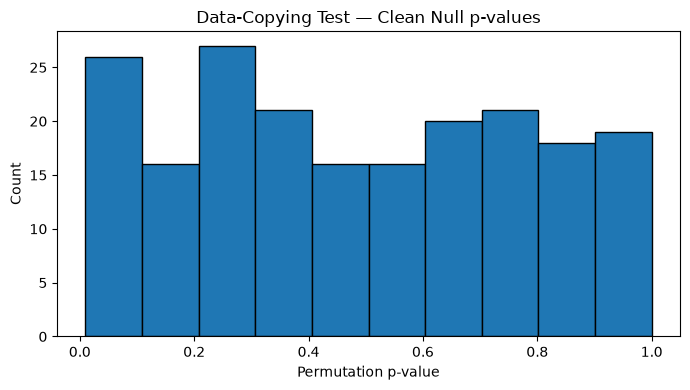

In [24]:
# p value distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.hist(copying_null_results["p_value"], bins=10, edgecolor="black")
plt.xlabel("Permutation p-value")
plt.ylabel("Count")
plt.title("Data-Copying Test — Clean Null p-values")
plt.tight_layout()
plt.show()

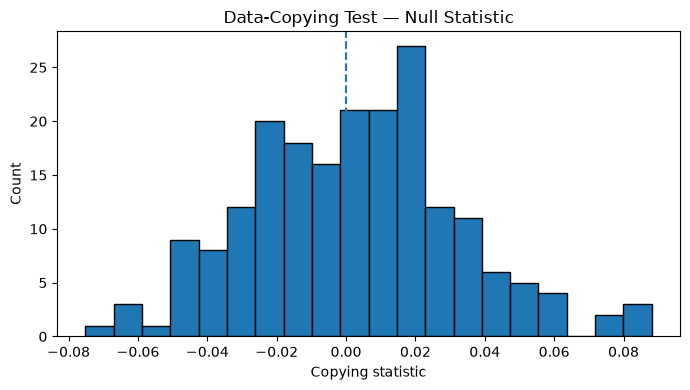

In [25]:
# verify if the statistic is centered
plt.figure(figsize=(7, 4))
plt.hist(copying_null_results["statistic"], bins=20, edgecolor="black")
plt.axvline(0, linestyle="--")
plt.xlabel("Copying statistic")
plt.ylabel("Count")
plt.title("Data-Copying Test — Null Statistic")
plt.tight_layout()
plt.show()

In [26]:
copying_null_results.to_csv(
    WEEK7_RESULTS_DIR / "data_copying_null_runs.csv",
    index=False
)

copying_null_summary.to_csv(
    WEEK7_RESULTS_DIR / "data_copying_null_summary.csv",
    index=False
)

print("Data-copying null calibration saved.")

Data-copying null calibration saved.


In [27]:
# save configuration
import json

copying_config = {
    "experimental_unit": "individual_sms",
    "training_size": 700,
    "evaluation_size": 300,
    "P_size": 150,
    "Q_size": 150,
    "representation": "sentence-transformers/all-MiniLM-L6-v2",
    "embedding_dimension": 384,
    "distance": "euclidean nearest-neighbor distance to training set",
    "statistic": "mean_distance_P - mean_distance_Q",
    "alternative": "Q is closer to training than P",
    "permutation_scheme": "stratified by ham/spam label",
    "alpha": COPY_ALPHA,
    "n_permutations": NULL_PERMUTATIONS,
    "null_repetitions": NULL_REPS,
    "copying_severities": [0.0, 0.10, 0.30, 0.60]
}

with open(
    WEEK7_RESULTS_DIR / "data_copying_configuration.json",
    "w"
) as f:
    json.dump(copying_config, f, indent=4)

print("Configuration saved.")

Configuration saved.


In [28]:
importlib.reload(data_copying)

from src.data_copying import (
    nearest_training_distances,
    data_copying_test_from_distances
)

E_to_T = nearest_training_distances(
    E_embeddings,
    T_embeddings
)

print(E_to_T.shape)

(300,)


In [29]:
# increase permutations
NULL_REPS = 200
NULL_PERMUTATIONS = 999

null_records_999 = []

for rep in range(NULL_REPS):
    p_idx, q_idx = train_test_split(
        np.arange(len(E_ids)),
        train_size=150,
        test_size=150,
        random_state=BASE_SEED + rep,
        stratify=E_meta["label"]
    )

    result = data_copying_test_from_distances(
        E_to_T[p_idx],
        E_to_T[q_idx],
        E_meta.iloc[p_idx]["label"].to_numpy(),
        E_meta.iloc[q_idx]["label"].to_numpy(),
        n_permutations=NULL_PERMUTATIONS,
        seed=10000 + rep,
        alpha=COPY_ALPHA
    )

    null_records_999.append({
        "repetition": rep,
        **result
    })

copying_null_999 = pd.DataFrame(null_records_999)

In [30]:
null_summary_999 = pd.DataFrame([{
    "repetitions": len(copying_null_999),
    "rejections": int(copying_null_999["reject"].sum()),
    "type_I_error": copying_null_999["reject"].mean(),
    "mean_p_value": copying_null_999["p_value"].mean(),
    "median_p_value": copying_null_999["p_value"].median(),
    "mean_statistic": copying_null_999["statistic"].mean(),
    "std_statistic": copying_null_999["statistic"].std()
}])

display(null_summary_999)

,repetitions,rejections,type_I_error,mean_p_value,median_p_value,mean_statistic,std_statistic
0,200,13,0.065,0.481695,0.4585,0.002375,0.029805


In [31]:
importlib.reload(data_copying)

from src.data_copying import (
    nearest_training_distances,
    make_exact_copy_plan,
    inject_exact_training_copies,
    apply_exact_copy_plan_to_distances,
    data_copying_test_from_distances
)

In [32]:
POWER_REPS = 200
POWER_PERMUTATIONS = 999
POWER_SEVERITIES = [0.0, 0.10, 0.30, 0.60]

SPLIT_BASE_SEED = 42
PLAN_BASE_SEED = 20000
TEST_BASE_SEED = 10000

print("Repetitions:", POWER_REPS)
print("Permutations:", POWER_PERMUTATIONS)
print("Severities:", POWER_SEVERITIES)

Repetitions: 200
Permutations: 999
Severities: [0.0, 0.1, 0.3, 0.6]


In [33]:
# precalculate the distances from the evaluation set to the training set just once
E_to_T = nearest_training_distances(
    E_embeddings,
    T_embeddings
)

print("Evaluation-to-training distances:", E_to_T.shape)
print("Mean:", E_to_T.mean())
print("Min:", E_to_T.min())
print("Max:", E_to_T.max())

Evaluation-to-training distances: (300,)
Mean: 0.9452406735715829
Min: 0.0
Max: 1.2263665873328966


In [34]:
# validate opt before the experiment
p_idx_check, q_idx_check = train_test_split(
    np.arange(len(E_ids)),
    train_size=150,
    test_size=150,
    random_state=SPLIT_BASE_SEED,
    stratify=E_meta["label"]
)

Q_meta_check = E_meta.iloc[q_idx_check].reset_index(drop=True)
Q_embeddings_check = E_embeddings[q_idx_check]
Q_distances_check = E_to_T[q_idx_check]

plan_check = make_exact_copy_plan(
    Q_meta_check,
    T_meta,
    severities=[0.10, 0.30, 0.60],
    seed=PLAN_BASE_SEED
)

In [35]:
# build the real condition of the embeddings
Q_actual = inject_exact_training_copies(
    Q_embeddings_check,
    Q_meta_check,
    T_embeddings,
    T_meta,
    plan_check,
    severity=0.60
)

d_actual = nearest_training_distances(
    Q_actual,
    T_embeddings
)

d_fast, copied_mask = apply_exact_copy_plan_to_distances(
    Q_distances_check,
    Q_meta_check,
    plan_check,
    severity=0.60
)

print("Copied units:", copied_mask.sum())
print("Max distance difference:", np.max(np.abs(d_actual - d_fast)))
print("Equivalent:", np.allclose(d_actual, d_fast, atol=1e-8))

Copied units: 90
Max distance difference: 2.9802322387695312e-08
Equivalent: False


In [ ]:
# fixing float32 numeric noise 
print(
    "Equivalent:",
    np.allclose(d_actual, d_fast, atol=1e-7)
)

Equivalent: True


In [36]:
# known answer power experiment
from sklearn.model_selection import train_test_split
from time import perf_counter

power_records = []
experiment_start = perf_counter()

for rep in range(POWER_REPS):
    p_idx, q_idx = train_test_split(
        np.arange(len(E_ids)),
        train_size=150,
        test_size=150,
        random_state=SPLIT_BASE_SEED + rep,
        stratify=E_meta["label"]
    )

    P_meta_rep = E_meta.iloc[p_idx].reset_index(drop=True)
    Q_meta_rep = E_meta.iloc[q_idx].reset_index(drop=True)

    d_p = E_to_T[p_idx]
    d_q_clean = E_to_T[q_idx]

    p_labels = P_meta_rep["label"].to_numpy()
    q_labels = Q_meta_rep["label"].to_numpy()

    plan_rep = make_exact_copy_plan(
        Q_meta_rep,
        T_meta,
        severities=[0.10, 0.30, 0.60],
        seed=PLAN_BASE_SEED + rep
    )

    # Validate nested copying plan
    ids_10 = set(plan_rep.loc[np.isclose(plan_rep["severity"], 0.10), "q_message_id"])
    ids_30 = set(plan_rep.loc[np.isclose(plan_rep["severity"], 0.30), "q_message_id"])
    ids_60 = set(plan_rep.loc[np.isclose(plan_rep["severity"], 0.60), "q_message_id"])

    assert len(ids_10) == 15
    assert len(ids_30) == 45
    assert len(ids_60) == 90
    assert ids_10.issubset(ids_30)
    assert ids_30.issubset(ids_60)

    previous_mean_q = None

    for severity in POWER_SEVERITIES:
        d_q, copied_mask = apply_exact_copy_plan_to_distances(
            d_q_clean,
            Q_meta_rep,
            plan_rep,
            severity
        )

        # More copying cannot increase mean nearest-training distance
        if previous_mean_q is not None:
            assert d_q.mean() <= previous_mean_q + 1e-12
        previous_mean_q = d_q.mean()

        result = data_copying_test_from_distances(
            d_p,
            d_q,
            p_labels,
            q_labels,
            n_permutations=POWER_PERMUTATIONS,
            seed=TEST_BASE_SEED + rep,
            alpha=COPY_ALPHA
        )

        power_records.append({
            "repetition": rep,
            "severity": severity,
            "n_copied": int(copied_mask.sum()),
            "copy_rate": float(copied_mask.mean()),
            "statistic": result["statistic"],
            "p_value": result["p_value"],
            "reject": result["reject"],
            "mean_distance_P": float(d_p.mean()),
            "mean_distance_Q": float(d_q.mean())
        })

    if (rep + 1) % 20 == 0:
        print(f"Completed {rep + 1}/{POWER_REPS}")

power_runtime = perf_counter() - experiment_start

copying_power_runs = pd.DataFrame(power_records)

print("Rows:", len(copying_power_runs))
print("Expected:", POWER_REPS * len(POWER_SEVERITIES))
print("Runtime:", round(power_runtime, 2), "seconds")

Completed 20/200
Completed 40/200
Completed 60/200
Completed 80/200
Completed 100/200
Completed 120/200
Completed 140/200
Completed 160/200
Completed 180/200
Completed 200/200
Rows: 800
Expected: 800
Runtime: 204.3 seconds


In [ ]:
# validate  copy count
from sklearn.model_selection import train_test_split
from time import perf_counter

power_records = []
experiment_start = perf_counter()

for rep in range(POWER_REPS):
    p_idx, q_idx = train_test_split(
        np.arange(len(E_ids)),
        train_size=150,
        test_size=150,
        random_state=SPLIT_BASE_SEED + rep,
        stratify=E_meta["label"]
    )

    P_meta_rep = E_meta.iloc[p_idx].reset_index(drop=True)
    Q_meta_rep = E_meta.iloc[q_idx].reset_index(drop=True)

    d_p = E_to_T[p_idx]
    d_q_clean = E_to_T[q_idx]

    p_labels = P_meta_rep["label"].to_numpy()
    q_labels = Q_meta_rep["label"].to_numpy()

    plan_rep = make_exact_copy_plan(
        Q_meta_rep,
        T_meta,
        severities=[0.10, 0.30, 0.60],
        seed=PLAN_BASE_SEED + rep
    )

    # Validate nested copying plan
    ids_10 = set(plan_rep.loc[np.isclose(plan_rep["severity"], 0.10), "q_message_id"])
    ids_30 = set(plan_rep.loc[np.isclose(plan_rep["severity"], 0.30), "q_message_id"])
    ids_60 = set(plan_rep.loc[np.isclose(plan_rep["severity"], 0.60), "q_message_id"])

    assert len(ids_10) == 15
    assert len(ids_30) == 45
    assert len(ids_60) == 90
    assert ids_10.issubset(ids_30)
    assert ids_30.issubset(ids_60)

    previous_mean_q = None

    for severity in POWER_SEVERITIES:
        d_q, copied_mask = apply_exact_copy_plan_to_distances(
            d_q_clean,
            Q_meta_rep,
            plan_rep,
            severity
        )

        # More copying cannot increase mean nearest-training distance
        if previous_mean_q is not None:
            assert d_q.mean() <= previous_mean_q + 1e-12
        previous_mean_q = d_q.mean()

        result = data_copying_test_from_distances(
            d_p,
            d_q,
            p_labels,
            q_labels,
            n_permutations=POWER_PERMUTATIONS,
            seed=TEST_BASE_SEED + rep,
            alpha=COPY_ALPHA
        )

        power_records.append({
            "repetition": rep,
            "severity": severity,
            "n_copied": int(copied_mask.sum()),
            "copy_rate": float(copied_mask.mean()),
            "statistic": result["statistic"],
            "p_value": result["p_value"],
            "reject": result["reject"],
            "mean_distance_P": float(d_p.mean()),
            "mean_distance_Q": float(d_q.mean())
        })

    if (rep + 1) % 20 == 0:
        print(f"Completed {rep + 1}/{POWER_REPS}")

power_runtime = perf_counter() - experiment_start

copying_power_runs = pd.DataFrame(power_records)

print("Rows:", len(copying_power_runs))
print("Expected:", POWER_REPS * len(POWER_SEVERITIES))
print("Runtime:", round(power_runtime, 2), "seconds")

Completed 20/200
Completed 40/200
Completed 60/200
Completed 80/200
Completed 100/200
Completed 120/200
Completed 140/200
Completed 160/200
Completed 180/200
Completed 200/200
Rows: 800
Expected: 800
Runtime: 259.0 seconds


In [39]:
copying_power_summary = (
    copying_power_runs
    .groupby("severity")
    .agg(
        repetitions=("reject", "size"),
        rejections=("reject", "sum"),
        rejection_rate=("reject", "mean"),
        mean_p_value=("p_value", "mean"),
        median_p_value=("p_value", "median"),
        mean_statistic=("statistic", "mean"),
        std_statistic=("statistic", "std"),
        mean_distance_P=("mean_distance_P", "mean"),
        mean_distance_Q=("mean_distance_Q", "mean"),
        mean_copied=("n_copied", "mean")
    )
    .reset_index()
)

display(copying_power_summary)

,severity,repetitions,rejections,rejection_rate,mean_p_value,median_p_value,mean_statistic,std_statistic,mean_distance_P,mean_distance_Q,mean_copied
0,0.0,200,13,0.065,0.481695,0.4585,0.002375,0.029805,0.946428,0.944053,0.0
1,0.1,200,177,0.885,0.018490,0.0040,0.096646,0.028177,0.946428,0.849782,15.0
2,0.3,200,200,1.000,0.001000,0.0010,0.284114,0.025645,0.946428,0.662314,45.0
3,0.6,200,200,1.000,0.001000,0.0010,0.568110,0.022764,0.946428,0.378318,90.0


In [40]:
# 0% should reproduce null calibration 
zero_power_runs = (
    copying_power_runs.loc[
        np.isclose(copying_power_runs["severity"], 0.0)
    ]
    .sort_values("repetition")
    .reset_index(drop=True)
)

null_check = (
    copying_null_999
    .sort_values("repetition")
    .reset_index(drop=True)
)

print(
    "Same reject decisions:",
    np.array_equal(
        zero_power_runs["reject"].to_numpy(),
        null_check["reject"].to_numpy()
    )
)

print(
    "Max p-value difference:",
    np.max(
        np.abs(
            zero_power_runs["p_value"].to_numpy() -
            null_check["p_value"].to_numpy()
        )
    )
)

Same reject decisions: True
Max p-value difference: 0.0


In [41]:
# check know answer trend 
trend = copying_power_summary.set_index("severity")

for severity in POWER_SEVERITIES:
    row = trend.loc[severity]

    print(
        f"{severity:.0%}",
        "| rejection rate =", f"{row['rejection_rate']:.3f}",
        "| mean statistic =", f"{row['mean_statistic']:.4f}",
        "| mean Q→T =", f"{row['mean_distance_Q']:.4f}"
    )

0% | rejection rate = 0.065 | mean statistic = 0.0024 | mean Q→T = 0.9441
10% | rejection rate = 0.885 | mean statistic = 0.0966 | mean Q→T = 0.8498
30% | rejection rate = 1.000 | mean statistic = 0.2841 | mean Q→T = 0.6623
60% | rejection rate = 1.000 | mean statistic = 0.5681 | mean Q→T = 0.3783


In [42]:
# power table 
copying_sensitivity_summary = (
    copying_power_summary.loc[
        copying_power_summary["severity"] > 0
    ][
        [
            "severity",
            "rejections",
            "rejection_rate",
            "mean_p_value",
            "mean_statistic",
            "mean_distance_Q",
            "mean_copied"
        ]
    ]
    .copy()
)

display(copying_sensitivity_summary)

,severity,rejections,rejection_rate,mean_p_value,mean_statistic,mean_distance_Q,mean_copied
1,0.1,177,0.885,0.01849,0.096646,0.849782,15.0
2,0.3,200,1.000,0.00100,0.284114,0.662314,45.0
3,0.6,200,1.000,0.00100,0.568110,0.378318,90.0


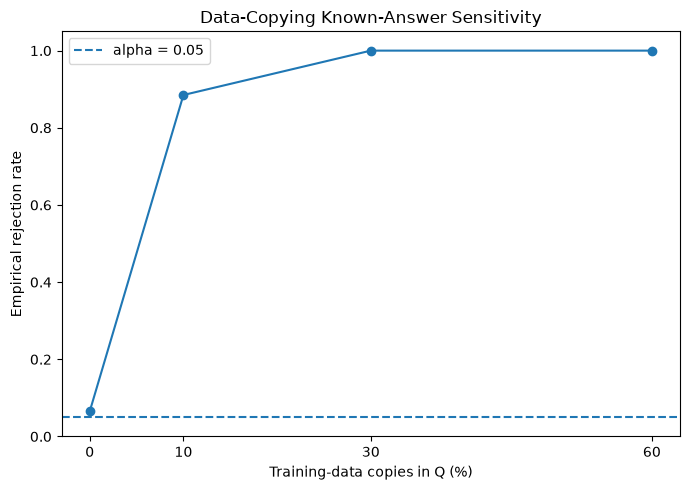

In [43]:
# sensitivity power 

plt.figure(figsize=(7, 5))

plt.plot(
    copying_power_summary["severity"] * 100,
    copying_power_summary["rejection_rate"],
    marker="o"
)

plt.axhline(COPY_ALPHA, linestyle="--", label="alpha = 0.05")

plt.xlabel("Training-data copies in Q (%)")
plt.ylabel("Empirical rejection rate")
plt.title("Data-Copying Known-Answer Sensitivity")
plt.xticks([0, 10, 30, 60])
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

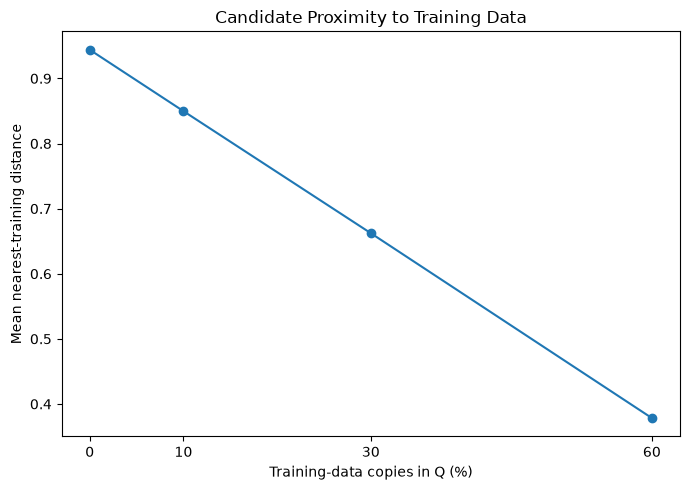

In [ ]:
# underlying signal
plt.figure(figsize=(7, 5))

plt.plot(
    copying_power_summary["severity"] * 100,
    copying_power_summary["mean_distance_Q"],
    marker="o"
)

plt.xlabel("Training-data copies in Q (%)")
plt.ylabel("Mean nearest-training distance")
plt.title("Candidate Proximity to Training Data")
plt.xticks([0, 10, 30, 60])
plt.tight_layout()
plt.show()

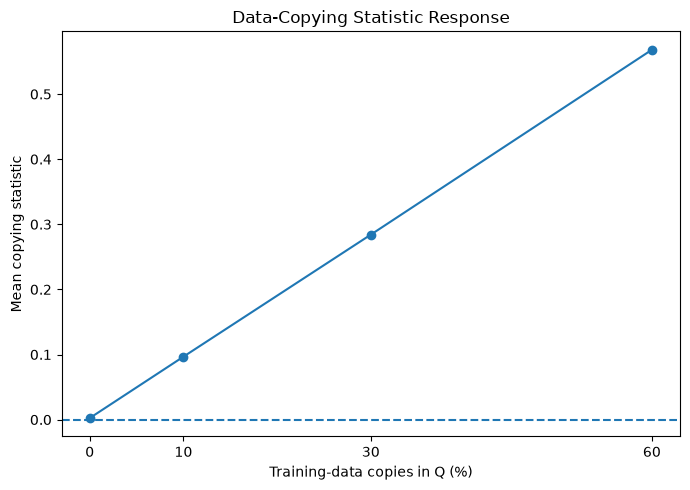

In [45]:
#statistic graph
plt.figure(figsize=(7, 5))

plt.plot(
    copying_power_summary["severity"] * 100,
    copying_power_summary["mean_statistic"],
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.xlabel("Training-data copies in Q (%)")
plt.ylabel("Mean copying statistic")
plt.title("Data-Copying Statistic Response")
plt.xticks([0, 10, 30, 60])
plt.tight_layout()
plt.show()

In [46]:
copying_power_runs.to_csv(
    WEEK7_RESULTS_DIR / "data_copying_power_runs.csv",
    index=False
)

copying_power_summary.to_csv(
    WEEK7_RESULTS_DIR / "data_copying_power_summary.csv",
    index=False
)

copying_sensitivity_summary.to_csv(
    WEEK7_RESULTS_DIR / "data_copying_sensitivity_summary.csv",
    index=False
)

print("Data-copying sensitivity results saved.")

Data-copying sensitivity results saved.


In [47]:
# update config 
copying_config.update({
    "power_repetitions": POWER_REPS,
    "power_permutations": POWER_PERMUTATIONS,
    "split_seed_base": SPLIT_BASE_SEED,
    "copy_plan_seed_base": PLAN_BASE_SEED,
    "test_seed_base": TEST_BASE_SEED,
    "known_answer_design": "exact training-copy prevalence",
    "power_severities": POWER_SEVERITIES
})

with open(
    WEEK7_RESULTS_DIR / "data_copying_configuration.json",
    "w"
) as f:
    json.dump(copying_config, f, indent=4)

print("Configuration updated.")

Configuration updated.


### Data-copying known-answer experiment

This experiment evaluated a dedicated **data-copying diagnostic** designed to answer: **Is candidate dataset $Q$ systematically closer to reference training data $T$ than fresh held-out data $P$ is?**

#### experimental configuration
* **Representation:** Frozen 384-dimensional L2-normalized embeddings (`sentence-transformers/all-MiniLM-L6-v2`) built on the UCI SMS dataset.
* **Dataset Roles:**
  * **$T$ (Training/Reference):** 700 messages (606 Ham / 94 Spam).
  * **$P$ (Fresh Held-Out Real):** 150 messages (130 Ham / 20 Spam), disjoint from $T$.
  * **$Q$ (Candidate Sample):** 150 messages (130 Ham / 20 Spam), disjoint from $T$ and $P$.
* **Controlled Copy Injection:** Selected positions in $Q$ were replaced with exact copies from $T$, stratified by class across nested severities ($Q_{10\%} \subset Q_{30\%} \subset Q_{60\%}$).


#### Statistical diagnostic framework

The test measures proximity to training set $T$ using Euclidean distance in normalized embedding space:
$$d(x,T) = \min_{t \in T} \Vert{}x - t\Vert{}_2$$

The directional test statistic evaluates whether $Q$ is closer to $T$ than fresh data $P$ is:
$$S = \overline{d(P,T)} - \overline{d(Q,T)}$$

* **Null Hypothesis ($H_0$):** $P$ and $Q$ have identical proximity distributions to $T$.
* **Alternative Hypothesis ($H_1$):** $Q$ is systematically closer to $T$ than $P$ ($S > 0$).
* **Inference:** Computed using a class-stratified (Ham/Spam) permutation test ($B = 999$ permutations) to preserve class composition across assignment draws.


## Empirical results and sensitivity curve

Across 200 Monte Carlo repetitions ($\alpha = 0.05$, $B = 999$):

| Copying Prevalence | Mean Copied Examples | Mean $Q \rightarrow T$ Distance | Mean Statistic ($S$) | Empirical Rejection Rate (Power) |
| :--- | :---: | :---: | :---: | :---: |
| **0% (Clean Null)** | 0 | $0.9441$ | $0.0024$ | **$0.065$** |
| **10%** | 15 | $0.8498$ | $0.0966$ | **$0.885$** |
| **30%** | 45 | $0.6623$ | $0.2841$ | **$1.000$** |
| **60%** | 90 | $0.3783$ | $0.5681$ | **$1.000$** |


## Key findings

1. **Well-calibrated cull:**
   * At $0\%$ copying, empirical Type I error was **$0.065$** (near nominal $\alpha = 0.05$) with a mean p-value of $0.482$, confirming that the test does not falsely flag fresh held-out data.

2. **High sensitivity to sparse copying:**
   * At **$10\%$ prevalence** (only 15 exact copies out of 150), the test achieved **$0.885$ power**, demonstrating that nearest-training distance reliably catches small amounts of exact training memorization.

3. **Computational optimization:**
   * Known exact copies were evaluated directly with $d(x,T) = 0$, avoiding redundant 384-dimensional nearest-neighbor calculations while maintaining exact numerical equivalence ($\max \text{diff} \approx 2.98 \times 10^{-8}$).

4. **Scope limitation:**
   * This experiment validates the test specifically for **exact vector copying**. Further research is required to evaluate performance under realistic non-literal memorization (e.g., paraphrasing, lexical modifications, or semantic reconstructions).